使用默认模式: 处理当前目录下所有 *.track, *.log, *.txt 文件
找到 10 个文件待处理...
正在处理: SEL_output.txt
  找到 8 个debug点, 计算出 4 个时间差
正在处理: BFS_output.txt
  找到 8 个debug点, 计算出 4 个时间差
正在处理: RED_output.txt
  找到 8 个debug点, 计算出 4 个时间差
正在处理: GEMV_output.txt
  找到 8 个debug点, 计算出 4 个时间差
正在处理: BS_output.txt
  找到 8 个debug点, 计算出 4 个时间差
正在处理: VA_output.txt
  找到 8 个debug点, 计算出 4 个时间差
正在处理: HST-S_output.txt
  找到 8 个debug点, 计算出 4 个时间差
正在处理: TS_output.txt
  找到 8 个debug点, 计算出 4 个时间差
正在处理: MLP_output.txt
  找到 8 个debug点, 计算出 4 个时间差
正在处理: NW_output.txt
  找到 8 个debug点, 计算出 4 个时间差

正在生成图表...
图表已保存到: debug_time_stacked_chart.png


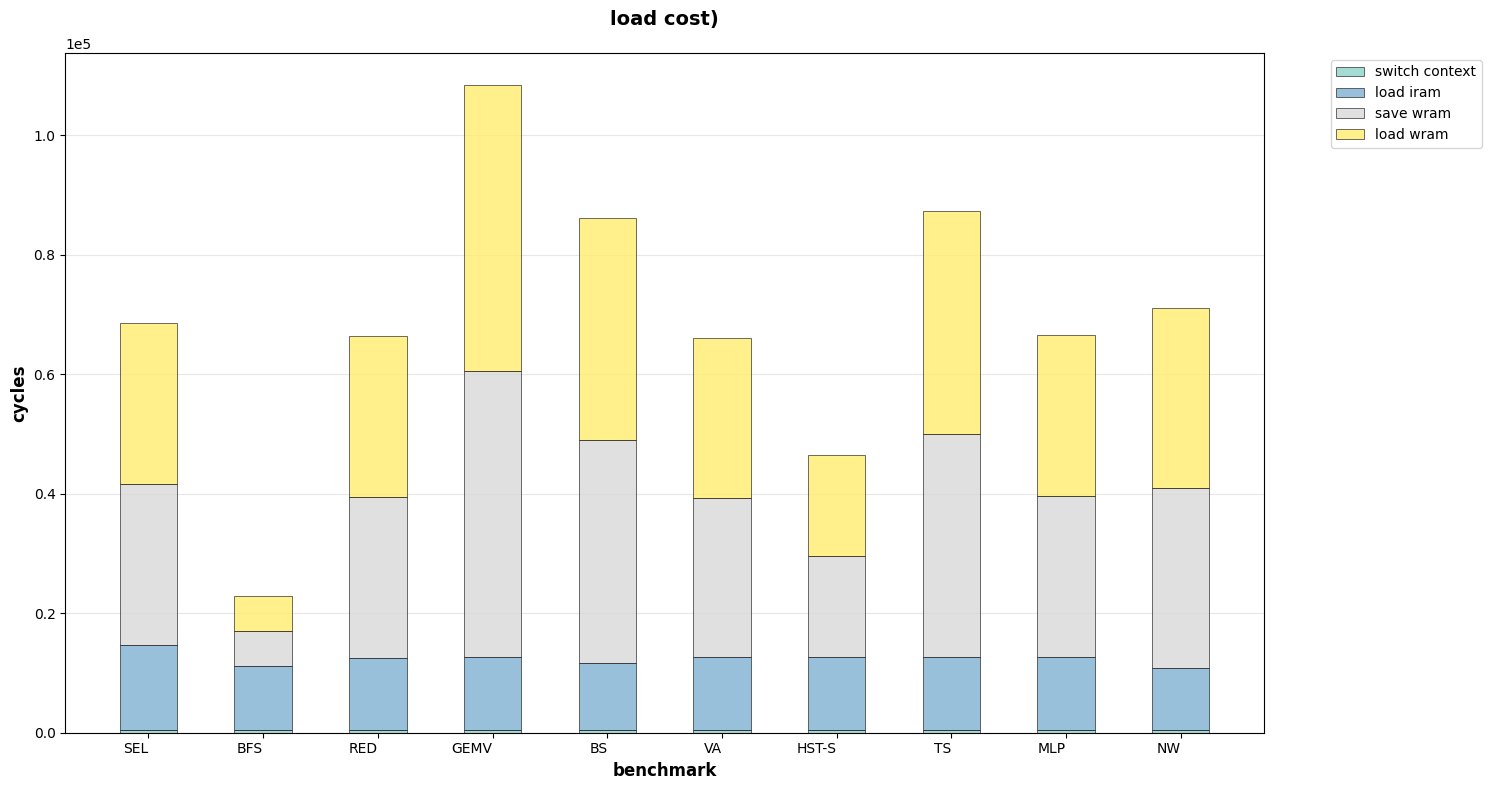

In [11]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import os
import re
import glob
import pandas as pd
from pathlib import Path
import argparse
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

class DebugTimeAnalyzer:
    def __init__(self):
        self.debug_pattern = re.compile(r'break point (\d+) happen in cycle:\s*(\d+)')
        self.time_pattern = re.compile(r'\*+time:(\d+)\*+')
        
    def parse_single_file(self, file_path):
        """解析单个track文件"""
        debug_points = {}
        current_time = None
        
        try:
            with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
                for line in f:
                    line = line.strip()
                    
                    # 匹配时间戳
                    time_match = self.time_pattern.search(line)
                    if time_match:
                        current_time = int(time_match.group(1))
                        continue
                    
                    # 匹配break point
                    debug_match = self.debug_pattern.search(line)
                    if debug_match:
                        point_id = int(debug_match.group(1))
                        cycle = int(debug_match.group(2))
                        debug_points[point_id] = {
                            'cycle': cycle,
                            'time': current_time
                        }
                        
        except Exception as e:
            print(f"解析文件 {file_path} 时出错: {e}")
            return None
            
        return debug_points
    
    def calculate_time_differences(self, debug_points):
        """计算相邻debug点之间的时间差"""
        time_diffs = {}
        
        # 获取所有debug点ID并排序
        point_ids = sorted(debug_points.keys())
        
        # 计算相邻点之间的差值 (debug1-debug0, debug3-debug2, debug5-debug4, ...)
        for i in range(0, len(point_ids)-1, 2):
            if i+1 < len(point_ids):
                point_a = point_ids[i]      # debug0, debug2, debug4, ...
                point_b = point_ids[i+1]    # debug1, debug3, debug5, ...
                
                if point_a in debug_points and point_b in debug_points:
                    cycle_a = debug_points[point_a]['cycle']
                    cycle_b = debug_points[point_b]['cycle']
                    time_diff = cycle_b - cycle_a
                    if(i==0):
                        name="save wram"
                    elif(i==2):
                        name="load wram"
                    elif(i==4):
                        name="load iram"
                    elif(i==6):
                        name="switch context"
                    else:
                        assert False, "Unexpected point index"
                    
                    time_diffs[name] = {
                        'point_a': point_a,
                        'point_b': point_b,
                        'cycle_a': cycle_a,
                        'cycle_b': cycle_b,
                        'time_diff': time_diff,
                        'time_a': debug_points[point_a].get('time'),
                        'time_b': debug_points[point_b].get('time')
                    }
        
        return time_diffs
    
    def process_multiple_files(self, file_patterns):
        """处理多个track文件"""
        all_results = {}
        
        # 收集所有匹配的文件
        all_files = []
        for pattern in file_patterns:
            files = glob.glob(pattern)
            all_files.extend(files)
        
        if not all_files:
            print("没有找到匹配的文件!")
            return None
        
        print(f"找到 {len(all_files)} 个文件待处理...")
        
        for file_path in all_files:
            print(f"正在处理: {file_path}")
            
            # 解析文件
            debug_points = self.parse_single_file(file_path)
            if debug_points is None:
                continue
                
            if not debug_points:
                print(f"  警告: 文件中未找到debug点")
                continue
            
            # 计算时间差
            time_diffs = self.calculate_time_differences(debug_points)
            
            # 存储结果
            file_name = Path(file_path).name
            all_results[file_name] = {
                'debug_points': debug_points,
                'time_diffs': time_diffs,
                'file_path': file_path
            }
            
            print(f"  找到 {len(debug_points)} 个debug点, 计算出 {len(time_diffs)} 个时间差")
        
        return all_results
    
    
    
    def clean_filename(self, filename):
        """清理文件名，去除_output后缀等"""
        # 去除文件扩展名
        name = Path(filename).stem
        
        # 去除_output后缀
        if name.endswith('_output'):
            name = name[:-7]  # 去除'_output'
        
        return name
    
    def create_bar_chart(self, results, save_path="debug_time_chart.png", show_plot=True):
        """创建柱状图显示debug时间差"""
        if not results:
            print("没有数据可以绘制图表")
            return None
        
        # 设置中文字体
        plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'SimHei']
        plt.rcParams['axes.unicode_minus'] = False
        
        # 准备数据
        file_names = []
        clean_names = []
        time_diff_data = {}
        
        # 收集所有可能的时间差类型
        all_diff_types = set()
        for file_name, data in results.items():
            time_diffs = data['time_diffs']
            all_diff_types.update(time_diffs.keys())
        
        # 按debug点顺序排序
        sorted_diff_types = sorted(all_diff_types, key=lambda x: int(re.search(r'debug(\d+)', x).group(1)) if re.search(r'debug(\d+)', x) else 0)
        
        # 为每种时间差类型准备数据列表
        for diff_type in sorted_diff_types:
            time_diff_data[diff_type] = []
        
        # 收集每个文件的数据
        for file_name, data in results.items():
            file_names.append(file_name)
            clean_names.append(self.clean_filename(file_name))
            time_diffs = data['time_diffs']
            
            # 为每种时间差类型添加数值，如果没有则添加0
            for diff_type in sorted_diff_types:
                if diff_type in time_diffs:
                    time_diff_data[diff_type].append(time_diffs[diff_type]['time_diff'])
                else:
                    time_diff_data[diff_type].append(0)
        
        # 创建图形
        fig, ax = plt.subplots(figsize=(max(12, len(file_names) * 1.5), 8))
        
        # 设置颜色
        colors = plt.cm.Set3(np.linspace(0, 1, len(sorted_diff_types)))
        
        # 创建堆叠柱状图
        bottom = np.zeros(len(file_names))
        bars = []
        
        for i, diff_type in enumerate(sorted_diff_types):
            values = time_diff_data[diff_type]
            bar = ax.bar(clean_names, values, bottom=bottom, 
                        label=diff_type, color=colors[i], 
                        alpha=0.8, edgecolor='black', linewidth=0.5, width=0.5)
            bars.append(bar)
            bottom += np.array(values)
        
        # 设置图表属性
        ax.set_xlabel('benchmark', fontsize=12, fontweight='bold')
        ax.set_ylabel('cycles', fontsize=12, fontweight='bold')
        ax.set_title('load cost)', 
                    fontsize=14, fontweight='bold', pad=20)
        
        # 旋转x轴标签以防重叠
        plt.xticks(rotation=0, ha='right')
        
        # 设置y轴格式
        ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
        
        # 添加图例
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
        
        # 添加网格
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_axisbelow(True)
        
        # 调整布局
        plt.tight_layout()
        
        # 保存图表
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"图表已保存到: {save_path}")
        
        # 显示图表
        if show_plot:
            plt.show()
        
        return fig, ax
   
    
    
def main(file_patterns=None, output_file="debug_analysis.csv", save_csv=True, 
         create_charts=True, chart_type="both"):
    """
    主函数 - 适合在Jupyter中调用
    
    参数:
    - file_patterns: 文件路径列表或通配符模式列表
    - output_file: 输出CSV文件名
    - save_csv: 是否保存CSV文件
    - create_charts: 是否创建图表
    - chart_type: 图表类型 ("stacked", "grouped", "both")
    """
    analyzer = DebugTimeAnalyzer()
    
    # 如果没有指定文件模式，尝试默认模式
    if file_patterns is None:
        file_patterns = ["*.track", "*.log", "*.txt"]
        print("使用默认模式: 处理当前目录下所有 *.track, *.log, *.txt 文件")
    
    # 处理文件
    results = analyzer.process_multiple_files(file_patterns)
    
    if results:
        
        
        
       
        
        # 创建图表
        if create_charts and len(results) > 0:
            print("\n正在生成图表...")
            
            if chart_type in ["stacked", "both"]:
                analyzer.create_bar_chart(results, "debug_time_stacked_chart.png", True)
            
    else:
        print("没有找到有效的结果")
    
    return results

def analyze_debug_files(file_patterns, output_file="debug_analysis.csv", save_csv=True, 
                       create_charts=True, chart_type="both"):
    """
    便捷函数 - 直接调用分析功能
    
    使用示例:
    # 分析单个文件并生成图表
    results = analyze_debug_files(["track1.log"])
    
    # 分析多个文件，只生成堆叠柱状图
    results = analyze_debug_files(["*.log"], chart_type="stacked")
    
    # 分析文件但不生成图表
    results = analyze_debug_files(["*.log"], create_charts=False)
    
    参数:
    - file_patterns: 文件路径列表或通配符模式
    - output_file: 输出CSV文件名
    - save_csv: 是否保存CSV文件
    - create_charts: 是否创建图表
    - chart_type: 图表类型 ("stacked"=堆叠图, "grouped"=分组图, "both"=两种都生成)
    """
    return main(file_patterns, output_file, save_csv, create_charts, chart_type)

def parse_command_line():
    """命令行参数解析 - 仅在命令行模式下使用"""
    parser = argparse.ArgumentParser(description='分析track文件中的debug时间差')
    parser.add_argument('files', nargs='+', help='track文件路径或通配符模式')
    parser.add_argument('-o', '--output', default='debug_analysis.csv', help='输出CSV文件名')
    parser.add_argument('--no-csv', action='store_true', help='不保存CSV文件')
    
    args = parser.parse_args()
    
    # 调用主函数
    main(args.files, args.output, not args.no_csv)

if __name__ == "__main__":
    # 检查是否在Jupyter环境中
    try:
       
        # 如果能执行到这里，说明在Jupyter环境中
        
        main()
        
    except NameError:
        # 不在Jupyter环境中，使用命令行参数解析
        import sys
        if len(sys.argv) == 1:
            # 没有命令行参数，使用默认模式
            main()
        else:
            # 有命令行参数，解析并执行
            parse_command_line()